## 오늘 할 일

- **Practice 1**: 겨울 전주 강수와 ENSO는 얼마나 강하게 함께 변할까?
- **Practice 2**: 전주 강수와 함께 변하는 SST 패턴은 어디에서 뚜렷할까? (지난 시간 회귀 지도와 비교)

## 상관계수 리마인드

$$
r = \frac{\overline{x'y'}}{\sigma_x \sigma_y} = \cos\theta, \qquad -1 \le r \le 1
$$

($x' = x - \bar{x}$ : 평균을 뺀 편차, $\overline{x'y'}$ : 공분산)

| | 회귀계수 $a$ (`slope`) | 상관계수 $r$ (`rvalue`) |
|---|---|---|
| 식 | $\overline{x'y'}\,/\,\sigma_x^2$ | $\overline{x'y'}\,/\,(\sigma_x\sigma_y)$ |
| 뜻 | $x$ 가 1 변할 때 $y$ 가 평균적으로 변하는 **양** | 점들이 직선에 얼마나 **가깝게 모여 있나** |
| 단위 | 있음 ($y$ 단위 / $x$ 단위) | 없음 |

분자(공분산)는 같고 분모만 다르다. 그래서 $a = r\,\dfrac{\sigma_y}{\sigma_x}$ 이다.

## Practice 1 Correlation analysis between winter (DEC) Precip_Jeonju and winter ENSO index

자료 준비는 Practice 05와 같다.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature 

from scipy import stats

In [2]:

################ Jeonju Precipitation index ################
#------------ Read .csv data -------------
data = pd.read_csv('../data/rn_20260928132312.csv', encoding='euc-kr', skiprows=7)
data.head()

,년월,지점,강수량(mm)
0,1980-01,146,37.1
1,1980-02,146,16.1
2,1980-03,146,63.4
3,1980-04,146,138.3
4,1980-05,146,116.7


In [3]:

#--------- Make a new Pandas Dataframe ----------
dates = pd.DatetimeIndex(data['년월'])  # set 'time' as date
precip = data['강수량(mm)']             # select precip data

In [4]:
pdata1 = pd.DataFrame({'time': dates, '강수량(mm)': precip}) 
pdata2 = pdata1.set_index(['time'])    # Set 'time' as index

In [5]:
#------ Convert Pandas Dataframe to xarray -----
# [0, :]: variable 방향 0번째(강수량), time은 전부 → 1차원 시계열
pr = pdata2.to_xarray().to_array()[0, :]
print(pr.shape)                               # (N,)

(552,)


In [6]:
#------ Calculate climatology -----
pr_clim = pr.sel(time=slice('1980-01','2022-12')).groupby('time.month').mean(dim='time')   

#---------- Calculate anomalies ------------
pranom = pr.groupby('time.month') - pr_clim

#------ Select December data -----
pr_dec = pranom[23::12]     # from 1981-12, Dec data only 
pr_dec = pr_dec.sel(time=slice('1982-12','2022-12'))  # from 1982-12 to 2022-12

In [7]:
######################## ENSO index ########################
#------------ Reading .nc data -------------
dset = xr.open_dataset('../data/sst.mnmean.nc')   
sst=dset.sst.sel()

In [8]:

#------------ Calculate Nino index ---------
nino34 = sst.where((sst.lat<5) & (sst.lat>-5) & (sst.lon>190) & (sst.lon<240), drop=True).mean(dim=['lat','lon'])

#---------- Calculate climatology ----------
clim = nino34.sel(time=slice('1982-01', '2022-12')).groupby('time.month').mean(dim='time')   

#---------- Calculate anomalies ------------
anom = (nino34.groupby('time.month') - clim)

#---------Take 3-month running mean---------
nino3mon = anom.rolling(time=3, center=True).mean()

In [9]:

#--------Pick up a specific season ---------
ninos = nino3mon[12::12]  # NDJ from 1982
ninos = ninos.sel(time=slice('1982-12','2022-12'))  # from 1982-12 to 2022-12]

## `scipy.stats.linregress` 로 상관계수 구하기

지난 시간과 같은 함수를 쓰고, 이번에는 출력 중 `rvalue` 와 `pvalue` 를 본다.

| 이름 | 뜻 |
|---|---|
| `rvalue` | 상관계수 $r$ |
| `pvalue` | 실제로는 관계가 없는데($r=0$) 우연히 이 정도 $r$ 이 나올 확률. **0.05보다 작으면 "통계적으로 유의하다"** |

> **회귀와 상관의 `pvalue` 는 같은 값이다.**
> $a = r\,\sigma_y/\sigma_x$ 이고 $\sigma_y/\sigma_x$ 는 항상 양수이므로, 기울기가 0이면 상관도 0이고 그 반대도 같다.
> 즉 둘은 같은 관계를 단위만 다르게 잰 값이라, "이 관계가 우연인가?"를 묻는 검정은 하나다.

In [18]:
##################  Correlation ##################### 
reg, interc, corr, pval ,stderr= stats.linregress(ninos, pr_dec)
print(reg, interc, corr, pval, stderr)

7.28167261224482 -0.1770785576209119 0.5124573321659517 0.0006138313216552504 1.9538400817972799


**회귀계수와 상관계수의 관계 확인**: $a = r\,\sigma_y / \sigma_x$

In [19]:
print('slope                :', reg)
print('r * std(y) / std(x)  :', corr * pr_dec.std().values / ninos.std().values)

slope                : 7.28167261224482
r * std(y) / std(x)  : 7.281672478519046


In [20]:
prprd = reg*ninos + interc  # For fitted line

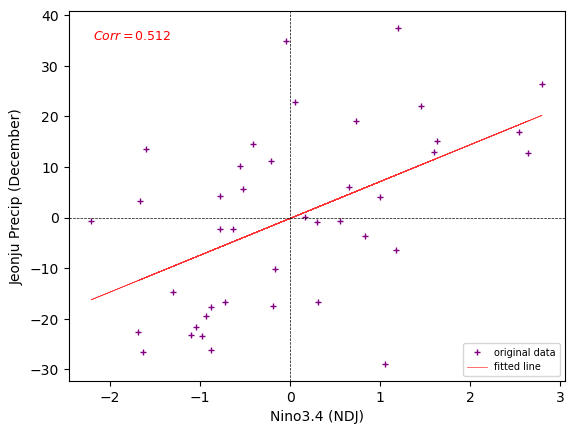

In [21]:
##################  Plotting ##################### 
fig, ax = plt.subplots()

ax.plot(ninos, pr_dec, '+', c='purple', markersize=4, label='original data')
ax.plot(ninos, prprd, c='r', lw=0.5, alpha=0.8, label='fitted line')
ax.axhline(0, color='k', linewidth=0.5, linestyle='dashed')
ax.axvline(0, color='k', linewidth=0.5, linestyle='dashed')
ax.set_xlabel('Nino3.4 (NDJ)')
ax.set_ylabel('Jeonju Precip (December)')
ax.legend(fontsize=7, loc='lower right')
txt=r'$Corr={:.3f}$'.format(corr)

ax.text(0.05, 0.95, txt, c='r', size=9, va='top', transform=ax.transAxes)

plt.show()

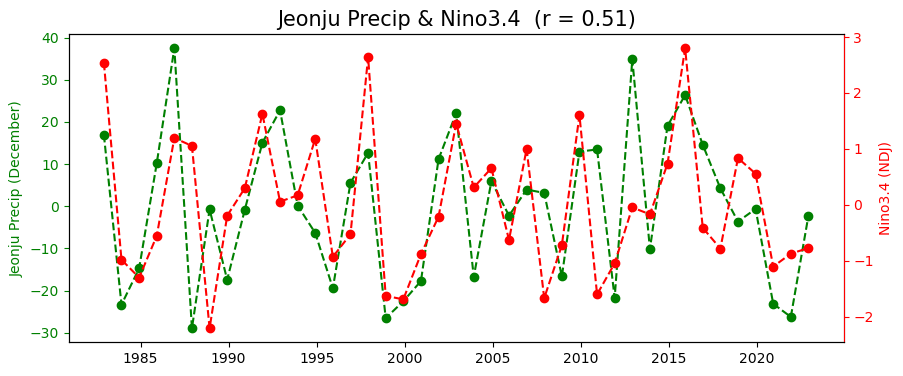

In [22]:
##################  Plotting ##################### 
fig, ax1 = plt.subplots(figsize=(10, 4), dpi=100)
ax1b = ax1.twinx()       # plot on the right axis

#--- Precip Graph
ax1.plot(pr_dec.time.values, pr_dec, color='g', marker='o', linestyle='dashed', linewidth=1.5)
ax1.set_ylabel('Jeonju Precip (December)', color='g')
ax1.tick_params(axis='y', color='g', labelcolor='g')
ax1.set_title(f'Jeonju Precip & Nino3.4  (r = {corr:.2f})', fontsize=15)

#--- Nino3.4 Graph
ax1b.plot(ninos.time.values, ninos, color='r', marker='o', linestyle='dashed', linewidth=1.5)
ax1b.set_ylabel('Nino3.4 (NDJ)', color='r')
ax1b.spines['right'].set_color('r')
ax1b.tick_params(axis='y', color='r', labelcolor='r')

plt.show()

## Practice 2 SST correlation pattern linked to Precip_Jeonju

In [15]:
#---------- Calculate climatology ----------
clim = sst.sel(time=slice('1982-01', '2022-12')).groupby('time.month').mean(dim='time')  
#---- Calculate anomalies and select DEC data ---
anomt = (sst.groupby('time.month') - clim)
anom = anomt.rolling(time=3, center=True).mean(dim='time')[12::12]    # Select from 1982
anom = anom.sel(time=slice('1982-12','2022-12'))  # from 1982-12 to 2022-12

/tmp/ipykernel_1691261/3640137812.py:5: FutureWarning: Reductions are applied along the rolling dimension(s) '['time']'. Passing the 'dim' kwarg to reduction operations has no effect.
  anom = anomt.rolling(time=3, center=True).mean(dim='time')[12::12]    # Select from 1982


Practice 05와 같은 코드다. 지난 시간에는 `reg` 를 그렸고, 이번에는 `corr` 와 `pval` 을 함께 본다.

In [16]:
reg, interc, corr, pval= np.apply_along_axis(lambda y,x: stats.linregress(x,y)[0:4],axis=0,arr=anom,x=pr_dec)

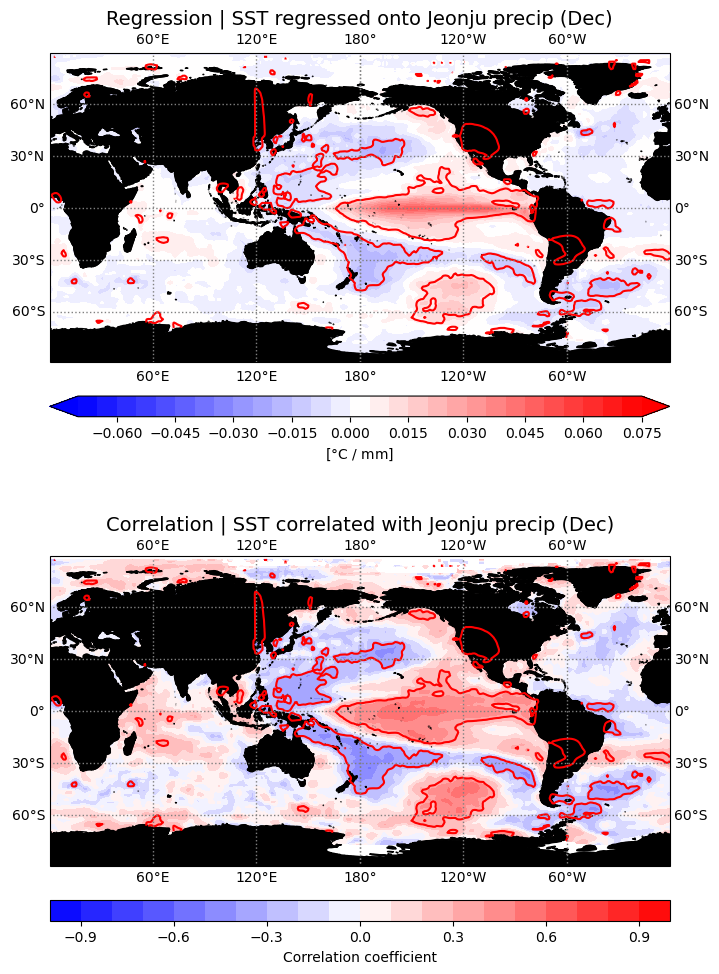

In [17]:
##########################  Plotting  ############################
fig = plt.figure(figsize=(8, 12))

lons = anom["lon"]
lats = anom["lat"]
land = cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='face', facecolor='black')

# ---------- Regression ----------
ax1 = plt.subplot(211, projection=ccrs.PlateCarree(180))
clevs = np.around(np.arange(-0.07, 0.0751, 0.005), 3)
a = ax1.contourf(lons, lats, reg, levels=clevs, cmap='bwr', extend='both', transform=ccrs.PlateCarree())
ax1.contour(lons, lats, pval, levels=[0.05], colors=['red'], transform=ccrs.PlateCarree())
plt.colorbar(a, ax=ax1, orientation='horizontal', pad=0.08, aspect=30, label='[$\\degree$C / mm]')
ax1.set_title('Regression | SST regressed onto Jeonju precip (Dec)', fontsize=14)
ax1.coastlines()
ax1.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')
ax1.add_feature(land)

# ---------- Correlation ----------
ax2 = plt.subplot(212, projection=ccrs.PlateCarree(180))
clevs = np.around(np.arange(-1, 1.1, 0.1), 3)
b = ax2.contourf(lons, lats, corr, levels=clevs, cmap='bwr', transform=ccrs.PlateCarree())
ax2.contour(lons, lats, pval, levels=[0.05], colors=['red'], transform=ccrs.PlateCarree())
plt.colorbar(b, ax=ax2, orientation='horizontal', pad=0.08, aspect=30, label='Correlation coefficient')
ax2.set_title('Correlation | SST correlated with Jeonju precip (Dec)', fontsize=14)
ax2.coastlines()
ax2.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')
ax2.add_feature(land)

plt.savefig('jeonju_precip_reg_corr_sst_dec.png')
plt.show()

### 두 지도 비교

- **진하게 보이는 지역은 다를 수 있다.** 회귀 지도는 SST 변동이 원래 큰 지역이 강조되고, 상관 지도는 변동 크기와 상관없이 관계가 일정한 지역이 강조된다.
- **빨간 선($p = 0.05$)은 두 지도에서 같다.** 회귀와 상관은 같은 검정 결과(`pvalue`)를 쓰기 때문이다.

### 상관분석 주의사항

- **인과관계가 아니다.** 전주 강수가 태평양 SST를 바꾸는 것이 아니다. 둘이 함께 변할 뿐이다.
- **선형 관계만 잡는다.** $r = 0$ 은 "선형 관계가 없다"는 뜻이지 "관계가 없다"는 뜻이 아니다.